# Stockroom: from transactions to business decisions

Prepared for Sakib Ahmed. This notebook analyzes **synthetic café data**, demonstrates validation and aggregation, and documents limitations. Run with Python 3 and `pip install -r requirements.txt`. Replace `DATA_FILE` with an exported dashboard CSV to analyze your own recorded transactions. The bundled data is anchored to October 30, 2026; app demo dates are anchored at first initialization.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
DATA_FILE = Path('sample_sales.csv')
df = pd.read_csv(DATA_FILE)
print(f'{len(df):,} records loaded')
print(df.head().to_string(index=False))

720 records loaded
         order_id       date product_id          product category  quantity  unit_price_myr  unit_cost_myr  revenue_myr  gross_profit_myr source
demo-2026-08-02-0 2026-08-02       P001       Flat white   Coffee        11            12.0            3.8        132.0              90.2 sample
demo-2026-08-02-1 2026-08-02       P002       Iced latte   Coffee         9            14.0            4.2        126.0              88.2 sample
demo-2026-08-02-2 2026-08-02       P003     Matcha latte      Tea         7            16.0            5.8        112.0              71.4 sample
demo-2026-08-02-3 2026-08-02       P004 Butter croissant   Bakery        14             9.5            3.5        133.0              84.0 sample
demo-2026-08-02-4 2026-08-02       P005     Banana bread   Bakery        12             8.5            2.8        102.0              68.4 sample


## 1. Validate before analyzing

Reject missing identifiers, invalid dates, fractional or negative quantities, negative prices/costs, duplicate IDs, and totals that disagree with recomputation. Do not silently discard invalid sales. Unit money amounts are converted to integer sen before calculations.

In [2]:
required = ['order_id','date','product_id','product','category','quantity','unit_price_myr','unit_cost_myr','revenue_myr','gross_profit_myr','source']
assert set(required).issubset(df.columns), 'Missing required columns'
assert not df[required].isna().any().any(), 'Missing values'
assert not df['order_id'].duplicated().any(), 'Duplicate IDs'
df['date'] = pd.to_datetime(df['date'], errors='raise')
for column in ['quantity','unit_price_myr','unit_cost_myr','revenue_myr','gross_profit_myr']:
    df[column] = pd.to_numeric(df[column], errors='raise')
assert (df['quantity'] > 0).all() and (df['quantity'] % 1 == 0).all()
assert (df[['unit_price_myr','unit_cost_myr']] >= 0).all().all()
df['price_sen'] = (df['unit_price_myr'] * 100).round().astype('int64')
df['cost_sen'] = (df['unit_cost_myr'] * 100).round().astype('int64')
df['revenue_sen'] = df['quantity'] * df['price_sen']
df['profit_sen'] = df['quantity'] * (df['price_sen'] - df['cost_sen'])
assert np.allclose(df['revenue_myr']*100, df['revenue_sen'])
assert np.allclose(df['gross_profit_myr']*100, df['profit_sen'])
print('PASS: required fields, unique IDs, dates, quantities, money, and totals')
print(f"Coverage: {df.date.min().date()} to {df.date.max().date()}")

PASS: required fields, unique IDs, dates, quantities, money, and totals
Coverage: 2026-08-02 to 2026-10-30


## 2. Define and calculate KPIs

Revenue is quantity × sale price. Gross profit is revenue less direct product cost. Gross margin is gross profit / revenue. Sales records are product lines, not complete orders or distinct customers.

In [3]:
revenue = df.revenue_sen.sum()/100
profit = df.profit_sen.sum()/100
margin = profit/revenue*100 if revenue else float('nan')
print(f'Revenue: MYR {revenue:,.2f}\nGross profit: MYR {profit:,.2f}\nGross margin: {margin:.1f}%\nUnits: {df.quantity.sum():,}')
products = df.groupby(['product_id','product','category'],as_index=False).agg(units=('quantity','sum'),revenue_sen=('revenue_sen','sum'),profit_sen=('profit_sen','sum'))
products['margin_pct'] = products.profit_sen.div(products.revenue_sen.replace(0,float('nan')))*100
products['revenue_share_pct'] = products.revenue_sen/(revenue*100)*100 if revenue else 0
products = products.sort_values('revenue_sen',ascending=False)
print(products.to_string(index=False))

Revenue: MYR 66,065.00
Gross profit: MYR 45,844.00
Gross margin: 69.4%
Units: 5,840
product_id          product category  units  revenue_sen  profit_sen  margin_pct  revenue_share_pct
      P003     Matcha latte      Tea    730      1168000      744600   63.750000          17.679558
      P002       Iced latte   Coffee    730      1022000      715400   70.000000          15.469613
      P006        Cold brew   Coffee    730       949000      715400   75.384615          14.364641
      P001       Flat white   Coffee    730       876000      598600   68.333333          13.259669
      P008   Peach iced tea      Tea    730       803000      613200   76.363636          12.154696
      P004 Butter croissant   Bakery    730       693500      438000   63.157895          10.497238
      P005     Banana bread   Bakery    730       620500      416100   67.058824           9.392265
      P007 Chocolate cookie   Bakery    730       474500      343100   72.307692           7.182320


## 3. Visualize daily performance and product contribution

Include zero-sales days in the daily series, and keep both axes labeled in MYR. This makes gaps and differences easier to interpret.

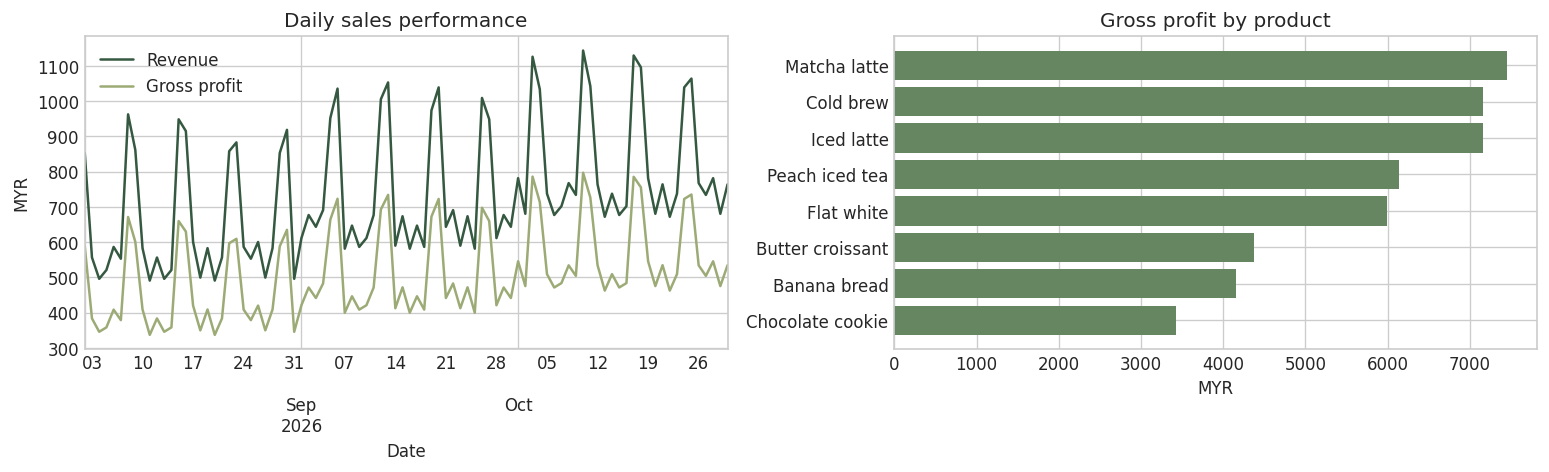

In [4]:
daily = df.groupby('date')[['revenue_sen','profit_sen']].sum().reindex(pd.date_range(df.date.min(),df.date.max()),fill_value=0)/100
plt.style.use('seaborn-v0_8-whitegrid')
fig,axes = plt.subplots(1,2,figsize=(13,4))
daily.rename(columns={'revenue_sen':'Revenue','profit_sen':'Gross profit'}).plot(ax=axes[0],color=['#355940','#9cab76'])
axes[0].set(title='Daily sales performance',xlabel='Date',ylabel='MYR')
ranked = products.sort_values('profit_sen')
axes[1].barh(ranked['product'],ranked.profit_sen/100,color='#668561')
axes[1].set(title='Gross profit by product',xlabel='MYR')
fig.tight_layout()
plt.show()

## 4. Compare weekday averages fairly

Compare revenue per calendar day rather than totals, because the period may contain unequal numbers of each weekday. Synthetic generation deliberately adds weekend demand; this is not evidence of real customer behavior.

In [5]:
daily['weekday'] = daily.index.day_name()
weekdays = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
weekday = daily.groupby('weekday').agg(mean_revenue_myr=('revenue_sen','mean'),days=('revenue_sen','size')).reindex(weekdays)
print(weekday.round(2).to_string())
end = df.date.max(); start = end-pd.Timedelta(days=29)
current = df[df.date.between(start,end)]
previous = df[df.date.between(start-pd.Timedelta(days=30),start-pd.Timedelta(days=1))]
prior = previous.revenue_sen.sum()
change = (current.revenue_sen.sum()/prior-1)*100 if prior else None
print(f'Latest 30-day revenue change: {change:.1f}%' if change is not None else 'Prior-period comparison unavailable')

           mean_revenue_myr  days
weekday                          
Monday               638.42    13
Tuesday              623.31    13
Wednesday            640.35    13
Thursday             632.85    13
Friday               643.65    13
Saturday            1000.00    12
Sunday               980.27    13
Latest 30-day revenue change: 12.5%


## 5. Findings and possible actions

The following statements are calculated from the loaded dataset. They describe the synthetic example and suggest hypotheses for real data; they are not claims of business impact.

In [6]:
top = products.iloc[0]
best_margin = products.dropna(subset=['margin_pct']).sort_values('margin_pct',ascending=False).iloc[0]
best_day = weekday.mean_revenue_myr.idxmax()
findings = [f"{top['product']} leads revenue with {top.revenue_share_pct:.1f}% of sales. In a real café, check its availability and supplier lead time before setting a reorder policy.",f"{best_margin['product']} has the highest gross margin at {best_margin.margin_pct:.1f}%. Test promotion or bundling only after considering demand and waste.",f"{best_day} has the highest average daily revenue at MYR {weekday.loc[best_day,'mean_revenue_myr']:,.2f}. For real data, compare staffing and stock needs across weekdays."]
for i,finding in enumerate(findings,1): print(f'{i}. {finding}')

1. Matcha latte leads revenue with 17.7% of sales. In a real café, check its availability and supplier lead time before setting a reorder policy.
2. Peach iced tea has the highest gross margin at 76.4%. Test promotion or bundling only after considering demand and waste.
3. Saturday has the highest average daily revenue at MYR 1,000.00. For real data, compare staffing and stock needs across weekdays.


## 6. Limitations and next steps

- All starting data is synthetic; weekend demand and growth are deliberately encoded.
- Gross profit excludes rent, wages, taxes, discounts, waste, returns, and payment fees.
- Price and cost are captured per sale; category/name come from the current product catalog at export.
- Stockouts may hide unmet demand; sales alone do not measure demand.
- No customer identifiers are present, so retention or customer lifetime value cannot be estimated.
- Validate future recommendations using real, permissioned transactions and operational feedback.
- Next improvements: supplier lead times, a stock-movement ledger, returns, and a read-only public demo with authenticated writes.